# 14 - When the band becomes an alarm: band edges as fault-detection limits

> "Can we retire the hand-tuned thresholds on 3,000 meters and alarm whenever a reading leaves its 90% band?" - Kestrel on-call engineer

That is the on-call engineer at Kestrel Operations, who carries the pager for the building
portfolio and the VM fleet, and who inherited a few thousand thresholds that somebody set by
eye years ago and nobody dares to touch. The proposal is attractive: the bands from notebook
12 are calibrated, they follow the daily rhythm, and nobody has to tune them. The sharper
statistical question hiding inside it: if a band edge becomes an **alarm limit**, what is its
**false-alarm rate** on healthy meters, what is its **detection delay** on broken ones,
against which kinds of fault, and is it any better than the detector a monitoring team would
build without a forecasting model at all?

The answer this notebook earns, in one breath: the band keeps its promise about false alarms,
approximately, and the promise is the problem; what it catches depends on the forecaster behind it,
and a forecaster that reads the latest readings can swallow a fault whole.

**What you will learn**

- Why a calibrated 90% band used as an alarm flags about 2.4 healthy readings per meter per
  day, why that is the guarantee working rather than failing (conformal outlier detection),
  and why false alarms must be counted both per reading and per alarm event.
- How to inject three textbook faults (freeze, step, drift) into copies of the test period
  and replay them through models that were fitted on clean history.
- Why a forecaster that leans on the last reading chases a fault until its band stops
  alarming, and why a forecast issued before the fault began holds on longer.
- How to score an alarm rule honestly: detection rate, median delay, false alarms per day,
  and the chance control that noisy rules cannot do without.
- How the bands compare with a robust z-score detector, and how to choose the band level by
  the cost of false alarms and missed faults.

**Where we are in the series.** Notebook 13 hunted frozen readings with a minimum-run-length
rule; this notebook asks what the forecasting bands of notebook 12 can catch on their own, and
part of the answer hands freezes straight back to notebook 13. Notebook 10 showed that a
building's misses arrive in bursts, notebook 11 built the walk-forward protocol we reuse
here, and notebook 15 takes up drift from the calibration side. From Part I we lean on
notebook 02 (alpha as a budget, the corrected quantile), notebook 03 (why a new score's rank
is uniform) and notebook 05 (CQR).

## 1. The arithmetic nobody does

Start with arithmetic, because nobody in the meeting did it. A calibrated 90% band is built to
miss about one reading in ten: that is the budget we chose in notebook 02, `ALPHA = 0.10`.
Used as an alarm limit, every miss is a flagged reading. A building meter reports 24 readings a
day, so a perfectly healthy meter flags about 24 x 0.10 = 2.4 readings a day, and 3,000 healthy
meters flag about 7,200 a day. A VM reports every five minutes, 288 readings a day, so one
healthy VM flags about 29. Nothing is broken in that picture. The band is doing exactly what it
promised, and the on-call engineer has just been promised a pager that never stops.

One definition before any measured number, because everything after it depends on the unit. A
**false alarm** in this notebook is one flagged reading on a healthy meter: a reading outside
its band, or, for the debounced rule of section 4, a reading that completes a qualifying run.
That is the unit alpha caps, and the unit of every `flagged/day` column. A pager, though, does
not ring once per reading; it rings once per **alarm event**, a run of consecutive flagged
readings (we also call it a storm). Events can never outnumber flagged readings, so whatever
caps the readings caps the events too; but when flags cluster there are far fewer events than
readings, and a detector can look noisy in one unit and quiet in the other. Field guide §21
asks for both, so every false-alarm table below carries an `events/day` column next to its
`flagged/day` column.

**Why it works, and why that is not enough.** A calibrated band used as an alarm is
**conformal outlier detection** (Bates, Candes, Lei, Romano and Sesia, 2023, is the modern
reference). In words: score the new reading's weirdness exactly as we scored the calibration
readings, and look at its rank among them. If the meter is healthy, the new reading is one
more card from the same deck, so its rank is uniformly random (notebook 03's leaderboard
argument), and the chance that it lands among the weirdest 10% is at most 10%. The formal
version is the conformal p-value, the split-conformal cousin of notebook 09's smoothed p-value:
the share of all the scores, the new one included, that are at least as weird as the new
reading,

$$p_{\text{new}} = \frac{1 + \#\{i \le n : s_i \ge s_{\text{new}}\}}{n + 1},$$

where $s_1, \dots, s_n$ are the $n$ calibration scores (the CQR score of notebook 05),
$s_{\text{new}}$ is the new reading's score and $\#\{\cdot\}$ counts. Alarming when
$p_{\text{new}} \le \alpha$ is, up to ties, the same
as alarming when the reading leaves the band; and if the healthy reading is exchangeable with
the calibration readings, $P(p_{\text{new}} \le \alpha) \le \alpha$.

Read that last sentence for what it leaves out. It is a statement about healthy meters only:
it caps the false-alarm rate (the type-1 error, in testing language) and says nothing about
faults. Whether a broken meter produces a large score, which is the alarm's power, depends
entirely on the forecaster behind the band: a fault is caught only if it makes the reading
look unlike the forecast, and sections 3 to 5 are about exactly that. Two caveats travel with
the guarantee. Hourly readings are not exchangeable, so the 10% is an approximation to
measure, not a theorem to quote (field guide §6, §14). And misses can cluster: notebook 10
found that on the building a miss makes the next miss far more likely, so alarms may arrive in
storms rather than evenly; the next cell measures how stormy our bands are. One more subtlety
for the fleet view: the cap is per reading, so across 3,000 meters a day without a false alarm
is essentially impossible. If the fleet needs an error rate of its own, Bates and colleagues
show that the Benjamini-Hochberg procedure (rank all the meters' p-values and flag the smallest
ones against a threshold that loosens with rank) applied to conformal p-values controls the
false discovery rate, the expected share of raised alarms that are false. We stay with one
meter at a time.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from threadpoolctl import threadpool_limits                 # installed with scikit-learn

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

# This notebook fits 60 small models and makes about 70 batched predictions.
# HistGradientBoosting spreads each call over every CPU core; on tables this small the
# coordination costs more than it saves, and on a busy laptop it can make every fit several
# times slower. One thread is plenty here, and it does not change a single prediction.
# (Keep the returned object: it holds the limit.)
THREAD_LIMIT = threadpool_limits(1, user_api="openmp")

The two Kestrel series come from the shared simulators, copied verbatim with their
docstrings, because the docstrings are the specification this notebook tests against: the
building's weekday rhythm and weather-driven HVAC load, and the VM's bursts, redeploy jumps and
legitimate flat lines at exactly 100%. The protocol helpers below them are the ones notebooks
11 and 12 use: the leakage-safe forecasting table with its baselines, the fast quantile GBM,
the walk-forward blocks with their h-row purge, the metrics, and notebook 02's corrected
quantile as a function. As in notebook 10, the 14-day same-hour features consume the first two
weeks of each series, which is one reason the VM evaluation is only eight days long. One
detail of this seed matters later: the VM's two redeploys fall during its fourth and twelfth
days, inside that warm-up, so its test period has no natural level shift, and every step it
contains is one we inject.

In [2]:
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_vm_cpu(n_days, seed, start="2019-01-01", base_pct=22.0, daily_amp=8.0,
                    bursts_per_day=5.0, n_redeploys=2):
    """Simulate 5-minute average CPU utilisation (%) for one Kestrel virtual machine.

    What the simulator bakes in (and what later notebooks test against):
    - A weak daily rhythm (busier in business hours) on top of a level that jumps when the
      service is redeployed. The jumps are sudden and unannounced.
    - Bursts: spikes arriving at random times (batch jobs, traffic surges) that decay over
      a few readings. They make the series bursty - the reason simple baselines are so hard
      to beat on cloud data.
    - Readings are clipped to [0, 100]. During heavy bursts the VM saturates and reports
      exactly 100.0 several readings in a row - a legitimate flat line that a naive
      stuck-sensor rule will mistake for a frozen gateway (notebook 13).

    Returns a DataFrame indexed by 5-minute timestamp with column `cpu_pct`.
    """
    rng = np.random.default_rng(seed)
    steps_per_day = 288
    n = steps_per_day * n_days
    idx = pd.date_range(start, periods=n, freq="5min")
    hour = idx.hour.to_numpy() + idx.minute.to_numpy() / 60.0

    # Level that jumps at redeployments.
    level = np.full(n, base_pct)
    for when in np.sort(rng.integers(steps_per_day * 2, n, size=n_redeploys)):
        level[when:] = level[when:] * rng.lognormal(0.0, 0.35)

    daily = daily_amp * np.clip(np.sin(np.pi * (hour - 7) / 12), 0.0, None)

    # Bursts: random arrivals, random heights, exponential decay over a few readings.
    burst = np.zeros(n)
    n_bursts = rng.poisson(bursts_per_day * n_days)
    for start_step, height, decay in zip(rng.integers(0, n, size=n_bursts),
                                         rng.exponential(35.0, size=n_bursts),
                                         rng.uniform(2.0, 10.0, size=n_bursts)):
        span = np.arange(start_step, min(start_step + int(6 * decay), n))
        burst[span] += height * np.exp(-(span - start_step) / decay)

    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.6 * ar[i - 1] + z[i]
    cpu = level + daily + burst + 2.5 * ar
    return pd.DataFrame({"cpu_pct": np.clip(cpu, 0.0, 100.0)}, index=idx)


b = simulate_building_load(730, seed=RANDOM_SEED)   # two years of hourly kWh, 2016-2017
v = simulate_vm_cpu(30, seed=RANDOM_SEED)           # thirty days of 5-minute CPU %
print(f"building: {len(b):,} hourly readings, {b.index[0]:%Y-%m-%d} to {b.index[-1]:%Y-%m-%d}")
print(f"VM:       {len(v):,} five-minute readings, {v.index[0]:%Y-%m-%d} to {v.index[-1]:%Y-%m-%d}")

building: 17,520 hourly readings, 2016-01-01 to 2017-12-30
VM:       8,640 five-minute readings, 2019-01-01 to 2019-01-30


In [3]:
def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()


BASELINES = ["last_value", "same_time_yesterday", "same_time_last_week", "median_14d_same_time"]
MODEL_FEATURES = ["last_value", "mean_last_day", "same_time_yesterday", "same_time_last_week",
                  "median_14d_same_time", "target_hour", "target_dow"]


def quantile_gbm(q, seed=20260707):
    """Gradient-boosted quantile model used by every Part II notebook.

    Small and fast on purpose (each fit takes well under a second). early_stopping=False
    matters: scikit-learn's automatic early stopping holds out a RANDOM 10% of rows, which
    on time-ordered data quietly lets the model peek at its own future.
    """
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=60,
                                         learning_rate=0.15, max_leaf_nodes=15,
                                         early_stopping=False, random_state=seed)


def walk_forward_blocks(n_rows, first_test_row, block_len, cal_len, h):
    """Yield (train_rows, cal_rows, test_rows) position arrays for rolling-origin evaluation.

    Rows are forecast origins in time order. For each block starting at row s:
    - test rows are [s, s + block_len): forecasts issued during the block;
    - calibration rows are the cal_len origins whose targets are all observed by time s,
      i.e. rows [s - h - cal_len + 1, s - h];
    - training rows end h rows before calibration starts, so no training target overlaps
      the calibration period (a purge of h rows).
    The model is re-fitted before every block on the training rows only.
    """
    s = first_test_row
    while s < n_rows:
        cal_end = s - h + 1
        cal_start = cal_end - cal_len
        train_end = cal_start - h
        assert train_end > 0, "not enough history before the first block"
        yield (np.arange(0, train_end), np.arange(cal_start, cal_end),
               np.arange(s, min(s + block_len, n_rows)))
        s += block_len


def interval_score(y, lo, hi, alpha):
    """Gneiting-Raftery interval score of a central (1 - alpha) band; lower is better.

    Width, plus a penalty of 2/alpha per unit of distance for every observation that lands
    outside the band. A band that is too narrow pays in misses; a band that is too wide
    pays in width. Averaged over observations.
    """
    y, lo, hi = np.asarray(y), np.asarray(lo), np.asarray(hi)
    return float(np.mean((hi - lo)
                         + (2.0 / alpha) * np.maximum(lo - y, 0.0)
                         + (2.0 / alpha) * np.maximum(y - hi, 0.0)))


def band_report(y, point, lo, hi, alpha):
    """MAE of the point forecast, plus coverage, mean width and interval score of the band."""
    y, point, lo, hi = map(np.asarray, (y, point, lo, hi))
    return {
        "MAE": float(np.mean(np.abs(y - point))),
        "coverage": float(np.mean((y >= lo) & (y <= hi))),
        "width": float(np.mean(hi - lo)),
        "interval_score": interval_score(y, lo, hi, alpha),
    }


def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])

The design decision that makes this notebook both cheap and realistic: every model is fitted
once, walk-forward, on clean history, exactly as in notebooks 11 and 12: six four-week blocks
for the building and four two-day blocks for the VM, a refit before each block, calibration on
the window that ends before the block starts, and an h-row purge (field guide §15). We keep
every fitted model. Faults come later, and only into copies of the test period: we rebuild the
forecasting table from the faulty copy and replay it through the models already fitted, with
no refit. That is what a deployed model experiences when a meter breaks in the middle of a
block: it was trained on healthy history and now reads whatever the meter sends.

Horizons are h = 1 and h = 24 for the building (next hour, day ahead) and h = 1 and h = 12 for
the VM (five minutes, one hour). The building model reads the temperature at the target hour,
treated as a known weather forecast. One modelling shortcut, stated plainly: the 95%, 99% and
99.8% bands reuse the 5% and 95% quantile models and let the conformal offset do all the
stretching. Quantile models refitted at 0.5% and 99.5% would give better-shaped tails; the
guarantee does not need them, and the replays stay at three models per block.

In [4]:
BAND_ALPHAS = (0.10, 0.05, 0.01, 0.002)   # 90%, 95%, 99% and 99.8% bands, one CQR offset each

FAMILIES = {
    # Protocol constants of the series: the same tables, blocks and windows as 11 and 12.
    "building": {"y": b["load_kwh"], "exog": b["temp_c"],
                 "features": MODEL_FEATURES + ["exog_at_target"],   # temp = known forecast
                 "period": 24, "horizons": (1, 24), "n_test": 24 * 7 * 24,
                 "block_len": 24 * 28, "cal_len": 24 * 28, "ceiling": None},
    "vm": {"y": v["cpu_pct"], "exog": None, "features": MODEL_FEATURES,
           "period": 288, "horizons": (1, 12), "n_test": 288 * 8,
           "block_len": 288 * 2, "cal_len": 288, "ceiling": 100.0},
}


def fit_alarm_bands(cfg, h):
    """Walk-forward CQR on CLEAN history, keeping every fitted model for later replays.

    For each block: fit the 5%, 50% and 95% quantile models on the training rows, score
    the calibration rows with the CQR score max(lo - y, y - hi), and store one offset
    q_hat per band level in BAND_ALPHAS that the calibration window can afford. The same
    5%/95% models serve every level: the conformal step alone stretches them to 95%, 99%
    or 99.8%, and the guarantee does not care that the raw band was fitted for 90%.
    Also stores notebook 02's offset for the persistence forecast (the last value), the
    purest example of a forecaster that chases its own input (section 3).
    """
    tab = make_direct_table(cfg["y"], h, cfg["period"], exog=cfg["exog"])
    X, y = tab[cfg["features"]], tab["target"].to_numpy()
    blocks = []
    for train, cal, test in walk_forward_blocks(len(tab), len(tab) - cfg["n_test"],
                                                cfg["block_len"], cfg["cal_len"], h):
        models = {q: quantile_gbm(q).fit(X.iloc[train], y[train])
                  for q in (ALPHA / 2, 0.5, 1 - ALPHA / 2)}
        scores = np.maximum(models[ALPHA / 2].predict(X.iloc[cal]) - y[cal],
                            y[cal] - models[1 - ALPHA / 2].predict(X.iloc[cal]))
        # A (1 - a) band needs at least (1 - a) / a calibration scores (field guide §1):
        # skip a level the window cannot afford rather than clip it into a fake promise.
        q_hat = {a: corrected_quantile(scores, a) for a in BAND_ALPHAS
                 if math.ceil((len(scores) + 1) * (1 - a)) <= len(scores)}
        q_persist = corrected_quantile(np.abs(y[cal] - tab["last_value"].to_numpy()[cal]), ALPHA)
        blocks.append({"models": models, "origins": tab.index[test],
                       "q_hat": q_hat, "q_persist": q_persist})
    return {"table": tab, "blocks": blocks, "h": h, "cfg": cfg}


def replay_bands(fit, reported, windows):
    """Rebuild the table from what each meter REPORTED and predict with the fitted models.

    No refit: a deployed model sees whatever the meter sends, faulty or not. `reported` is
    a list of series (one per fault episode, or just the clean series) and `windows` the
    reading times to replay for each. All series go through the models together, one batch
    per walk-forward block, because hundreds of tiny predict calls cost more than one big
    one. Returns one DataFrame per series, indexed by reading time, with the reported value
    `y`, the median forecast `mid`, the raw quantile band `lo`/`hi`, one CQR offset `q_<a>`
    per band level, and the persistence band ingredients `last_value` and `q_persist`.
    """
    cfg = fit["cfg"]
    pieces = []
    for i, (y_rep, times) in enumerate(zip(reported, windows)):
        tab = make_direct_table(y_rep, fit["h"], cfg["period"], exog=cfg["exog"])
        assert tab.index.equals(fit["table"].index), "a fault must not change which rows exist"
        pieces.append(tab[tab["target_time"].isin(times)].assign(series=i))
    rows = pd.concat(pieces)
    out = pd.DataFrame({"series": rows["series"].to_numpy(), "y": rows["target"].to_numpy(),
                        "last_value": rows["last_value"].to_numpy()},
                       index=pd.DatetimeIndex(rows["target_time"], name="reading_time"))
    out = out.reindex(columns=["series", "y", "mid", "lo", "hi", "last_value", "q_persist"]
                      + [f"q_{a}" for a in fit["blocks"][0]["q_hat"]])
    for blk in fit["blocks"]:
        mine = rows.index.isin(blk["origins"])   # forecasts issued during this block
        if mine.any():
            X = rows.loc[mine, cfg["features"]]
            out.loc[mine, ["mid", "lo", "hi"]] = np.column_stack(
                [blk["models"][q].predict(X) for q in (0.5, ALPHA / 2, 1 - ALPHA / 2)])
            out.loc[mine, "q_persist"] = blk["q_persist"]
            for a, q in blk["q_hat"].items():
                out.loc[mine, f"q_{a}"] = q
    out = out[out["mid"].notna()]   # keep only forecasts issued inside the test blocks
    return [part.drop(columns="series") for _, part in out.groupby("series", sort=True)]


fits, clean = {}, {}
for fam, cfg in FAMILIES.items():
    for h in cfg["horizons"]:
        fits[fam, h] = fit_alarm_bands(cfg, h)
        clean[fam, h] = replay_bands(fits[fam, h], [cfg["y"]], [cfg["y"].index])[0]

rows = []
for (fam, h), bands in clean.items():
    q = bands["q_0.1"]
    rows.append({"family": fam, "horizon h": h, "test readings": len(bands),
                 **band_report(bands["y"], bands["mid"], bands["lo"] - q, bands["hi"] + q, ALPHA)})
pd.DataFrame(rows).set_index(["family", "horizon h"]).round(3)

test readings     MAE  coverage   width  interval_score
family   horizon h                                                         
building 1                   4032   9.851     0.893  43.931          57.473
         24                  4032  15.777     0.898  63.728          89.783
vm       1                   2304   2.674     0.895  12.956          23.048
         12                  2304   5.730     0.902  24.647          52.298

These bands follow the same CQR recipe as notebook 12, without its quantile-crossing repair,
which barely matters here: coverage matches 12's to the third decimal and every width is within
0.03 of 12's. On the building, coverage is 0.893 at h = 1 and 0.898 at h = 24, with widths of
43.9 and 63.7 kWh; on the VM, 0.895 and 0.902, with widths of
12.96 and 24.65 points of CPU. Turn coverage upside down and you have the alarm rate: 10.7% of
healthy building readings leave their h = 1 band, and 10.2% leave their h = 24 band. Notice one
thing before we spend these bands: the day-ahead band is about 45% wider than the next-hour
band, so its edges sit farther from its forecast and a fault must be bigger to cross them. That
fact returns in section 4 to complicate a clean story. And nothing in this table is a fault
yet: every reading is healthy, which is exactly why the next cell can count false alarms.

In [5]:
def outside_band(bands, a):
    """True where the reported reading falls outside the CQR band at level 1 - a."""
    q = bands[f"q_{a}"]
    return ((bands["y"] < bands["lo"] - q) | (bands["y"] > bands["hi"] + q)).to_numpy()


def storm_lengths(flags):
    """Lengths of the runs of consecutive alarmed readings: one run = one alarm event (a storm)."""
    edges = np.diff(np.r_[0, flags.astype(int), 0])
    return np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)


def per_day(flags, period):
    """Alarms per day counted both ways: flagged readings, and alarm events (runs of them)."""
    n_days = len(flags) / period
    return flags.sum() / n_days, len(storm_lengths(flags)) / n_days


rows = []
for (fam, h), bands in clean.items():
    period = FAMILIES[fam]["period"]
    flags = outside_band(bands, ALPHA)
    storms = storm_lengths(flags)
    flagged_99, events_99 = per_day(outside_band(bands, 0.01), period)
    rows.append({"family": fam, "horizon h": h,
                 "readings per day": period,
                 "budget flagged/day": period * ALPHA,
                 "flagged/day": per_day(flags, period)[0],
                 "events/day": per_day(flags, period)[1],
                 "mean storm": storms.mean(),
                 "storm if independent": 1 / (1 - flags.mean()),   # mean run of coin flips
                 "longest storm": storms.max(),
                 "99% flagged/day": flagged_99, "99% events/day": events_99,
                 "99% width": (bands["hi"] - bands["lo"] + 2 * bands["q_0.01"]).mean()})
healthy = pd.DataFrame(rows).set_index(["family", "horizon h"])

N_METERS = 3_000
flagged, events = healthy.loc[("building", 24), ["flagged/day", "events/day"]]
print(f"{N_METERS:,} meters x {flagged:.2f} flagged readings per meter per day = "
      f"{N_METERS * flagged:,.0f} false alarms a day, in {N_METERS * events:,.0f} alarm events, "
      f"every one of them on a healthy meter")
healthy.round(2)

3,000 meters x 2.45 flagged readings per meter per day = 7,339 false alarms a day, in 3,804 alarm events, every one of them on a healthy meter


readings per day  budget flagged/day  flagged/day  events/day  mean storm  storm if independent  longest storm  \
family   horizon h                                                                                                                   
building 1                        24                 2.4         2.58        2.15        1.20                  1.12              6   
         24                       24                 2.4         2.45        1.27        1.93                  1.11              9   
vm       1                       288                28.8        30.25       25.50        1.19                  1.12              4   
         12                      288                28.8        28.25        7.00        4.04                  1.11             12   

                    99% flagged/day  99% events/day  99% width  
family   horizon h                                              
building 1                     0.23            0.22      80.17  
         24                    0.31            0.15     139.67  
vm       1                     1.88            1.88      73.50  
         12                    3.00            1.38      89.01

The arithmetic survives contact with the data. A healthy building meter flags 2.58 readings a
day against its h = 1 band and 2.45 against its h = 24 band, for a budget of 2.4; across 3,000
meters that is 7,339 false alarms a day from meters with nothing wrong with them, arriving as
3,804 alarm events. A healthy VM flags 30.25 and 28.25 readings a day, for a budget of 28.8.
Every flagged-reading rate sits close to its budget, a little above it at both building
horizons and at VM h = 1 (10.7%, 10.2% and 10.5% of readings instead of 10%) and a little
below it at VM h = 12 (9.8%): the cap holds in
expectation under exchangeability, and our hours are only approximately exchangeable.

The event columns turn notebook 10's question (do misses travel together?) into pager traffic.
If misses were independent coin flips at the measured rate, a storm would average 1.11 to 1.12
readings (the `storm if independent` column, 1 / (1 - miss rate)). The next-step bands come
close: 1.20 readings on the building and 1.19 on the VM, because a forecaster that reads the
last reading absorbs most of the previous surprise, so their events per day (2.15 and 25.50)
are nearly as many as their flagged readings. The longer horizons storm. At h = 24 the
building's 2.45 flagged readings arrive as 1.27 events a day averaging 1.93 readings, the
longest 9 hours; at h = 12 the VM's 28.25 arrive as 7.00 events a day averaging 4.04 readings,
the longest 12
readings (an hour). That agrees with notebook 10 once you notice which forecast it used:
its strongly clustered building misses came from a same-hour-last-week band, a forecast that
never reads the latest value and so behaves like our long horizons, while its next-step VM
misses chained only in short pairs (a miss was followed by another about 18% of the time,
against 12.8% for a calendar shuffle), much like the 1.2-reading storms of our h = 1 bands.
The nuance is the lesson: how stormy an alarm
is depends on the horizon of the forecast behind it. A storm is one bad forecast that
stays bad for a while: a burst nobody saw coming, a Monday that started late.

The last three columns are the first cheap fix anyone proposes, a stricter edge. The 99% band
cuts the healthy building to 0.23 and 0.31 flagged readings a day (0.22 and 0.15 events), at
the price of widths of 80.17 and 139.67 kWh. On the VM it still flags 1.88 and 3.00 readings a
day (1.88 and 1.38 events) while being 73.50 and 89.01 points of CPU wide, most of
the possible range, because a healthy VM's life includes bursts
that no five-minute forecast anticipates. What this table cannot say is whether any of these
bands would notice a broken meter. For that we need broken meters.

## 2. Three faults

Real faults come without labels (the public building and cloud traces do not say which
readings were broken), so we make our own: injected into copies of the series, where we know
the truth. Three textbook shapes cover most of what goes wrong with a meter or a monitoring
agent:

| Fault | What the meter reports | Everyday cause | Why it is hard to see |
|---|---|---|---|
| freeze | the last good reading, repeated | a gateway that stops polling and resends its cache | every frozen value is a plausible value (notebook 13) |
| step | the true value times (1 + size), from one reading to the next | a miswired current clamp, a chiller stuck on, a runaway process | it is not hard: this is the easy one |
| drift | the true value times a factor that ramps from 1 to (1 + size) | a sensor slowly losing its calibration, a fouling filter | no single reading differs much from the one before |

Sizes and lengths: on the building a 48-hour freeze, a 48-hour step of 30% up or down, and a
one-week drift that ends 30% off; on the VM a six-hour freeze, a six-hour step of 50%, and a
two-day drift that ends 50% off (the VM's healthy swings are larger relative to its level, so
its faults must be too). We draw 40 episodes per fault type and family, with random starts
inside the test period and random signs.

In [6]:
def inject_fault(y, kind, start, length, size):
    """Return a copy of series y with one fault injected at positions [start, start + length).

    kind = "freeze": the gateway repeats the last good reading, y[start - 1], for the whole
                     window (size is ignored) - notebook 13's stuck value.
    kind = "step":   every reading in the window is multiplied by (1 + size): size = 0.3 is a
                     sudden 30% jump (a miswired current clamp, a chiller stuck on), -0.3 a
                     sudden 30% drop.
    kind = "drift":  a linear ramp from 0 to `size` over the window (a sensor slowly losing
                     its calibration): the last faulty reading is off by the full `size`.
    After the window the meter is repaired and reports the truth again. The input series is
    never modified, so comparing the two shows exactly what the fault did.
    """
    values = y.to_numpy(dtype=float).copy()
    window = slice(start, start + length)
    if kind == "freeze":
        values[window] = values[start - 1]
    elif kind == "step":
        values[window] = values[window] * (1.0 + size)
    elif kind == "drift":
        values[window] = values[window] * (1.0 + size * np.arange(1, length + 1) / length)
    else:
        raise ValueError(f"unknown fault kind: {kind}")
    return pd.Series(np.maximum(values, 0.0), index=y.index, name=y.name)


def reported_series(ep):
    """What the meter reports during one episode (a VM cannot report more than 100%)."""
    cfg = FAMILIES[ep["family"]]
    reported = inject_fault(cfg["y"], ep["kind"], ep["start"], ep["length"], ep["size"])
    return reported if cfg["ceiling"] is None else reported.clip(upper=cfg["ceiling"])


FAULTS = {  # kind -> (length in readings, size), per family
    "building": {"step": (48, 0.30), "freeze": (48, 0.0), "drift": (168, 0.30)},
    "vm": {"step": (72, 0.50), "freeze": (72, 0.0), "drift": (576, 0.50)},
}
N_EPISODES = 40   # per fault type and family, at random starts inside the test period

rng = np.random.default_rng(RANDOM_SEED)
episodes = []
for fam, cfg in FAMILIES.items():
    test_times = clean[fam, cfg["horizons"][0]].index
    first, last = cfg["y"].index.get_loc(test_times[0]), cfg["y"].index.get_loc(test_times[-1])
    for kind, (length, size) in FAULTS[fam].items():
        # Start at least one day into the test period, so every rule has a healthy run-up.
        starts = rng.integers(first + cfg["period"], last - length + 2, size=N_EPISODES)
        signs = rng.choice([-1.0, 1.0], size=N_EPISODES)
        episodes += [{"family": fam, "kind": kind, "start": int(s), "length": length,
                      "size": float(sg * size)} for s, sg in zip(starts, signs)]

pd.DataFrame(episodes).groupby(["family", "kind"]).agg(
    episodes=("start", "size"), length_readings=("length", "first"),
    size=("size", lambda s: s.abs().max()), upward=("size", lambda s: int((s > 0).sum())))

episodes  length_readings  size  upward
family   kind                                           
building drift         40              168   0.3      24
         freeze        40               48   0.0       0
         step          40               48   0.3      19
vm       drift         40              576   0.5      19
         freeze        40               72   0.0       0
         step          40               72   0.5      13

That is 240 episodes: 40 per fault type and family, each starting at least a day into the test
period and ending inside it. The coin for the direction landed upward for 19 of the 40
building steps, 24 of the 40 building drifts, 13 of the 40 VM steps and 19 of the 40 VM
drifts; freezes have no direction. One honesty note on the design, before any detector sees
these faults: they are cleaner than real ones. One fault at a time, a perfect step, a
perfectly linear ramp, a gateway that freezes on an exact value: real faults arrive mixed,
partial and noisy, so every detection number in this notebook is closer to a best case than
to a field measurement. Here is one hand-picked example of each on the building.

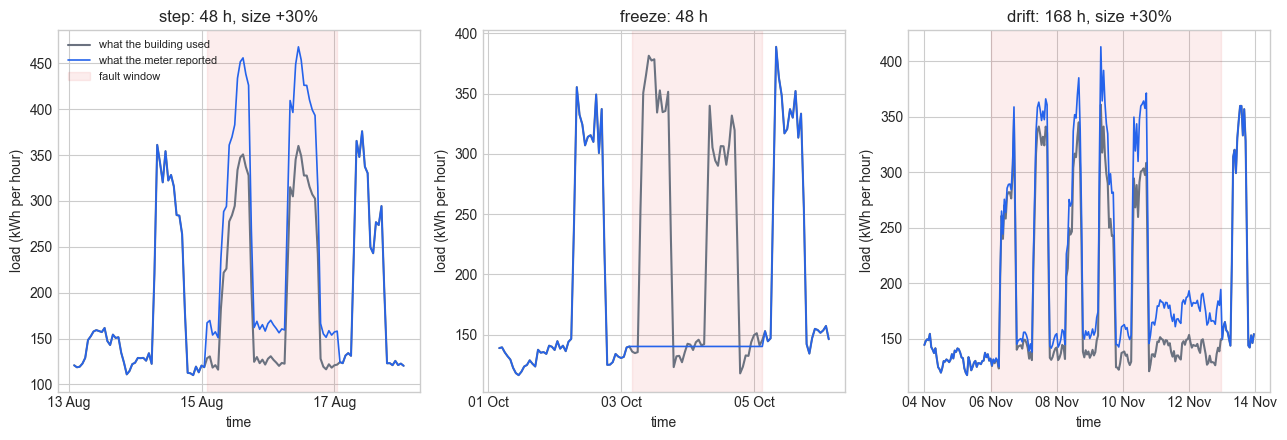

In [7]:
y_b = b["load_kwh"]
examples = {  # hand-picked starts inside the test period, so each picture is easy to read
    "step": ("2017-08-15 02:00", 48, 0.30),
    "freeze": ("2017-10-03 04:00", 48, 0.0),
    "drift": ("2017-11-06 00:00", 168, 0.30),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (kind, (when, length, size)) in zip(axes, examples.items()):
    s = y_b.index.get_loc(pd.Timestamp(when))
    reported = inject_fault(y_b, kind, s, length, size)
    view = slice(s - 48, s + length + 24)
    ax.plot(y_b.index[view], y_b.iloc[view], color=GRAY, linewidth=1.5,
            label="what the building used")
    ax.plot(reported.index[view], reported.iloc[view], color=BLUE, linewidth=1.2,
            label="what the meter reported")
    ax.axvspan(y_b.index[s], y_b.index[s + length - 1], color=RED, alpha=0.08,
               label="fault window")
    ax.set_title(f"{kind}: {length} h" + (f", size {size:+.0%}" if kind != "freeze" else ""))
    ax.set_xlabel("time")
    ax.set_ylabel("load (kWh per hour)")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Left, a step: at 02:00 on Tuesday 15 August the meter starts reporting 30% more than the
building uses, through two working days. At the occupied peaks the gap is over 100 kWh (about
450-470 kWh reported against about 350 used); at night it is 35-40 kWh. Middle, a freeze: at
04:00 on Tuesday 3 October the gateway locks onto the night reading of about 140 kWh and
repeats it for 48 hours, plausible at night and absurd at noon, when the building uses 300-380
kWh. Keep that contrast in mind; it decides which freezes a forecaster can catch. Right, a
drift: from Monday 6 November the reported load creeps upward until it is 30% too high a week
later. On Monday the two lines are indistinguishable, by the weekend the reported night load
sits visibly above the truth, and at no hour does anything jump. Of the three, only the step
announces itself; the other two have to be inferred from what the reading should have been,
which is exactly what a forecast band claims to know.

## 3. The forecaster chases the fault

Here is the mechanism that decides most of what follows. The band is built around a forecast,
and the forecast is built from features: the last reading, the mean of the last day, the same
hour yesterday and last week, the 14-day median. Every one of those features is computed from
what the meter reported. Once a meter starts reporting nonsense, every forecast issued after
that moment is built on nonsense too. A forecaster that leans on the last reading follows the
fault: after a step its next forecast starts from the stepped value, during a freeze its
forecast is the frozen value, during a slow drift it drifts along. Its band moves with the
fault, and stops alarming.

A forecast issued before the fault began cannot be fooled this way, because it was made from
healthy readings. At h = 24, every forecast for the first day of a fault was issued before the
fault started. That is the case for alarming against day-ahead forecasts, and we can watch it
on the step from section 2, replaying the faulty copy through the h = 1 and h = 24 models that
were fitted on clean data.

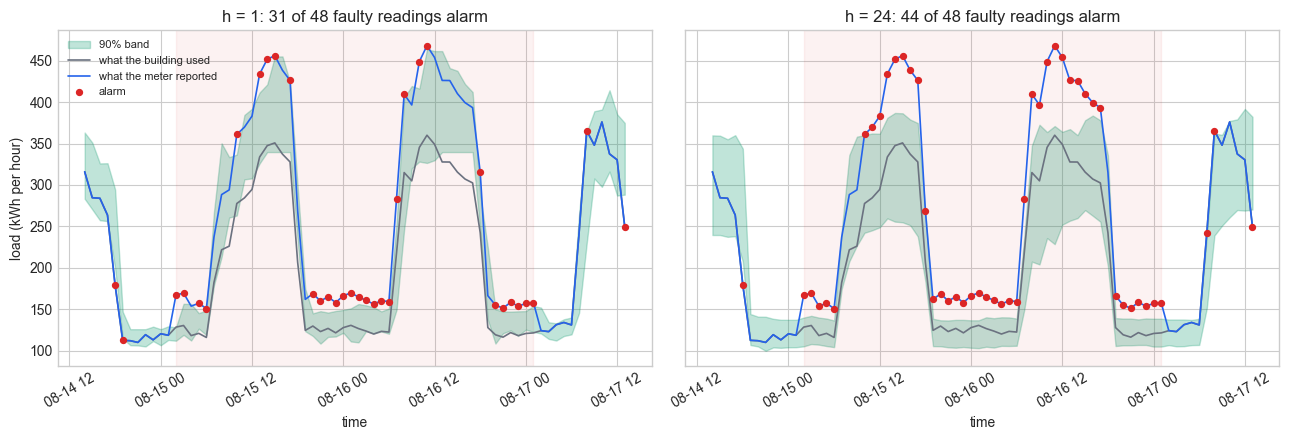

In [8]:
when, length, size = examples["step"]
s = y_b.index.get_loc(pd.Timestamp(when))
reported = inject_fault(y_b, "step", s, length, size)
view_times = y_b.index[s - 12:s + length + 12]
fault_times = y_b.index[s:s + length]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, h in zip(axes, (1, 24)):
    bands = replay_bands(fits["building", h], [reported], [view_times])[0]
    alarm = outside_band(bands, ALPHA)
    in_fault = bands.index.isin(fault_times)
    ax.fill_between(bands.index, bands["lo"] - bands["q_0.1"], bands["hi"] + bands["q_0.1"],
                    color=GREEN, alpha=0.25, label="90% band")
    ax.plot(bands.index, y_b.loc[bands.index], color=GRAY, linewidth=1.2,
            label="what the building used")
    ax.plot(bands.index, bands["y"], color=BLUE, linewidth=1.2, label="what the meter reported")
    ax.scatter(bands.index[alarm], bands["y"][alarm], color=RED, s=18, zorder=3, label="alarm")
    ax.axvspan(fault_times[0], fault_times[-1], color=RED, alpha=0.06)
    ax.set_title(f"h = {h}: {alarm[in_fault].sum()} of {in_fault.sum()} faulty readings alarm")
    ax.set_xlabel("time")
    ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("load (kWh per hour)")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Same fault, two forecasters. On the left, the h = 1 band alarms on 31 of the 48 faulty
readings, the very first one at 02:00 included; on the right, the h = 24 band alarms on 44 of
48. Watch where the left band goes. During the occupied hours it climbs after the faulty
readings: every next-hour forecast starts from a stepped last value, and by the afternoon of
the second day the band has climbed onto the stepped readings and most of them sit inside
it. At night it does not follow: the model's other features (the same hour yesterday and last
week, the 14-day median, the hour of the day) still insist that 03:00 in this building means
about 120 kWh, and the stepped night readings alarm nearly all night. The right band hardly moves:
for the first 24 hours every forecast was issued before the fault began, and on the second
day the model leans on last week and the 14-day median, which are still clean. One episode
is an anecdote, though, so the next cell replays all 240 episodes once and averages, for the
40 building episodes of each fault, the share of faulty readings that alarm, hour by hour
since onset. It adds the purest chaser as a reference: a persistence band, last value
plus or minus notebook 02's corrected quantile of the absolute one-step change, calibrated on
the same windows.

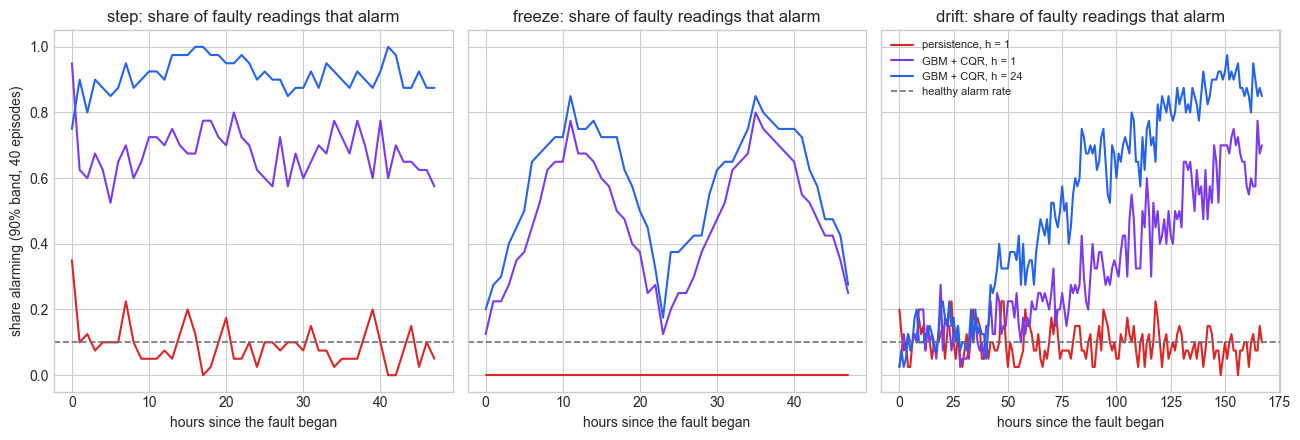

first reading  hours 1-23  hours 24+
step   persistence, h = 1           0.35        0.09       0.08
       GBM + CQR, h = 1             0.95        0.69       0.66
       GBM + CQR, h = 24            0.75        0.93       0.90
freeze persistence, h = 1           0.00        0.00       0.00
       GBM + CQR, h = 1             0.12        0.47       0.50
       GBM + CQR, h = 24            0.20        0.58       0.59
drift  persistence, h = 1           0.20        0.11       0.10
       GBM + CQR, h = 1             0.02        0.13       0.36
       GBM + CQR, h = 24            0.02        0.13       0.59

In [9]:
# Replay every episode once, both families and both horizons, through the fitted models.
# Sections 4 to 6 reuse these replays; nothing below refits anything.
replays = [{} for _ in episodes]
for fam, cfg in FAMILIES.items():
    ids = [i for i, ep in enumerate(episodes) if ep["family"] == fam]
    reported = [reported_series(episodes[i]) for i in ids]
    windows = [cfg["y"].index[episodes[i]["start"]:episodes[i]["start"] + episodes[i]["length"]]
               for i in ids]
    for h in cfg["horizons"]:
        for i, rep in zip(ids, replay_bands(fits[fam, h], reported, windows)):
            replays[i][h] = rep

FORECASTERS = {  # name -> (band, horizon, colour)
    "persistence, h = 1": ("persistence", 1, RED),
    "GBM + CQR, h = 1": ("cqr", 1, PURPLE),
    "GBM + CQR, h = 24": ("cqr", 24, BLUE),
}


def chase_profile(kind, band, h):
    """Share of faulty readings that alarm, by hour since onset, over the building episodes."""
    flags = []
    for ep, rep in zip(episodes, replays):
        if ep["family"] == "building" and ep["kind"] == kind:
            bands = rep[h]
            if band == "persistence":   # notebook 02's band around the last value
                miss = np.abs(bands["y"] - bands["last_value"]) > bands["q_persist"]
                flags.append(miss.to_numpy())
            else:
                flags.append(outside_band(bands, ALPHA))
    return np.mean(flags, axis=0)


fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
summary = {}
for ax, kind in zip(axes, ("step", "freeze", "drift")):
    for name, (band, h, color) in FORECASTERS.items():
        prof = chase_profile(kind, band, h)
        ax.plot(np.arange(len(prof)), prof, color=color, linewidth=1.5, label=name)
        summary[kind, name] = {"first reading": prof[0], "hours 1-23": prof[1:24].mean(),
                               "hours 24+": prof[24:].mean()}
    ax.axhline(ALPHA, color=GRAY, linestyle="--", linewidth=1.2, label="healthy alarm rate")
    ax.set_title(f"{kind}: share of faulty readings that alarm")
    ax.set_xlabel("hours since the fault began")
axes[0].set_ylabel(f"share alarming (90% band, {N_EPISODES} episodes)")
axes[2].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(summary).T.round(2)

Across 40 episodes per fault the picture sharpens into three behaviours.

Persistence (red) is the textbook chase. On a step it alarms on the first faulty reading in
only 35% of episodes, because its band has to accommodate ordinary hour-to-hour jumps such as
the morning ramp, so a 30% step at night often fits inside. From the second reading on it
alarms 9% of the time during the first day and 8% after: the healthy rate. It absorbed the
step after one reading. On a freeze it alarms on exactly 0.00 of the faulty readings, because
the frozen value is the last value, so every reading sits at the centre of its own band. On a
drift it stays at the healthy rate throughout (the 0.20 on the first reading is 8 episodes in
40 alarming for ordinary reasons: one hour into the ramp, the reading has moved by 0.2%).

The GBM at h = 1 (purple) chases part of the way: 95% of first step readings alarm, then 69%
during the first day and 66% after. It follows the stepped last value, but its seasonal
features keep pulling the forecast back towards what this hour normally looks like. The
h = 24 GBM (blue) chases least once the fault is under way: 93% of step readings alarm in
hours 1-23 and 90% after, 58-59% of freeze readings against 47-50% for h = 1, and 59% of drift
readings from the second day on against 36%. Its first step reading alarms less often (75%
against 95%) for the reason flagged in section 1: its band is 45% wider.

Two shapes in the curves deserve a sentence each. The freeze curves rise and fall on a
24-hour rhythm, peaking about 11 and 35 hours after onset: a frozen value is most wrong half a
day after it froze (a night reading at noon, a noon reading at night) and plausible again a
full day later. The drift curves sit at the healthy rate for about two days (h = 24) or four
(h = 1) before climbing: a drift is invisible until it has grown to a fair fraction of a band
width, and a forecaster that reads the drifted readings postpones that moment. What the
picture does not say is that h = 24 always wins. It chases less and it is wider, and section 4
shows which of the two forces wins under each alarm rule.

## 4. Alarm rules and their price

An alarm rule decides which readings raise an alarm. Three candidates, all from the field
guide's toolbox (field guide §21):

- **90% band, any reading**: alarm whenever a reading leaves its band. The proposal on the
  table.
- **90% band, 3 in a row**: alarm only when three consecutive readings are outside. This is
  debouncing: a single surprise is forgiven, a persistent one is not.
- **99% band, any reading**: a stricter edge, the same CQR models with a larger offset.

For each rule and fault type we score the 40 episodes on three numbers: the **detection rate**
(the share of episodes with at least one alarm inside the fault window), the median
detection delay (hours from onset to the first alarm, over the detected episodes), and the
false alarms per day on the whole healthy test period, in both of section 1's units.

One trap before the table. A rule that flags 2.4 healthy readings a day will "detect" almost
any 48-hour fault, including the ones that never happened. So every detection rate gets a
control column, the **chance rate**: the share of the same windows, on the healthy series with
no fault injected, in which the rule flagged a reading anyway. A detection rate means something
only by how far it clears its chance rate.

In [10]:
def k_in_a_row(flags, k=3):
    """Debounce: alarm at a reading only if it and the k - 1 readings before it are all flagged."""
    out = flags.copy()
    for j in range(1, k):
        out[j:] &= flags[:-j]
        out[:j] = False
    return out


RULES = {
    "90% band, any": lambda bands: outside_band(bands, 0.10),
    "90% band, 3 in a row": lambda bands: k_in_a_row(outside_band(bands, 0.10), 3),
    "99% band, any": lambda bands: outside_band(bands, 0.01),
}


def score_episode(flags_fault, flags_healthy, i0, length, steps_per_hour):
    """Detection, delay and the chance control for one episode and one detector.

    The control is the same window on the healthy series: `chance` says whether the rule
    flagged a reading there anyway, `chance_delay_h` when it first did (the timing check
    of section 5 compares that with `delay_h`).
    """
    hits = np.flatnonzero(flags_fault[i0:i0 + length])
    false_hits = np.flatnonzero(flags_healthy[i0:i0 + length])
    return {"hit": hits.size > 0,
            "delay_h": hits[0] / steps_per_hour if hits.size else np.nan,
            "chance": false_hits.size > 0,
            "chance_delay_h": false_hits[0] / steps_per_hour if false_hits.size else np.nan}


false_alarms, records = {}, []   # (flagged readings/day, alarm events/day) on healthy data
for (fam, h), bands in clean.items():
    for rule, fn in RULES.items():
        false_alarms[fam, f"h={h}", rule] = per_day(fn(bands), FAMILIES[fam]["period"])
for ep, rep in zip(episodes, replays):
    cfg = FAMILIES[ep["family"]]
    for h in cfg["horizons"]:
        healthy_bands = clean[ep["family"], h]
        faulty_bands = healthy_bands.copy()
        faulty_bands.loc[rep[h].index, rep[h].columns] = rep[h]   # splice the fault window in
        i0 = healthy_bands.index.get_loc(rep[h].index[0])
        for rule, fn in RULES.items():
            records.append({"family": ep["family"], "kind": ep["kind"],
                            "horizon": f"h={h}", "rule": rule,
                            **score_episode(fn(faulty_bands), fn(healthy_bands), i0,
                                            ep["length"], cfg["period"] / 24)})
results = pd.DataFrame(records)


def detector_table(res, fam):
    """One row per detector: healthy alarms/day (both units), then hit, chance, delay per fault."""
    agg = (res[res["family"] == fam]
           .groupby(["horizon", "rule", "kind"])
           .agg(hit=("hit", "mean"), chance=("chance", "mean"), delay_h=("delay_h", "median")))
    wide = agg.unstack("kind").swaplevel(axis=1)[["step", "freeze", "drift"]]
    wide.insert(0, ("healthy", "flagged/day"), [false_alarms[(fam, *d)][0] for d in wide.index])
    wide.insert(1, ("healthy", "events/day"), [false_alarms[(fam, *d)][1] for d in wide.index])
    return wide


detector_table(results, "building").round(2)

kind                             healthy             step                freeze                drift               
                             flagged/day events/day   hit chance delay_h    hit chance delay_h   hit chance delay_h
horizon rule                                                                                                       
h=1     90% band, 3 in a row        0.13       0.08  1.00   0.15     2.5   0.92   0.15     9.0  1.00   0.40    66.5
        90% band, any               2.58       2.15  1.00   1.00     0.0   0.95   0.98     7.0  1.00   1.00     8.0
        99% band, any               0.23       0.22  1.00   0.42     0.0   0.92   0.25     7.0  1.00   0.65    49.0
h=24    90% band, 3 in a row        0.58       0.25  1.00   0.55     2.0   1.00   0.25     7.0  1.00   0.82    44.5
        90% band, any               2.45       1.27  1.00   1.00     0.0   1.00   0.92     4.5  1.00   1.00    11.0
        99% band, any               0.31       0.15  0.95   0.10     5.0   0.92   0.12     7.0  0.92   0.42    73.0

Read the any-reading rows first, because they are the proposal on the table. They detect
everything: 100% of steps, 95-100% of freezes and 100% of drifts, with median delays of 0 to 11
hours. Now read their chance columns: 1.00, 0.98 and 1.00 at h = 1, and 1.00, 0.92 and 1.00 at
h = 24. On healthy windows of the same length, with nothing wrong, the rule flags a reading
just as surely. A rule with 2.4 false alarms a day "detects" faults the way a stopped clock
tells the time, and its drift delays of 8 and 11 hours are the time to the first unlucky alarm,
not the time for the drift to become visible (the timing check of section 5: in 37 and 31 of
the 40 drift windows the first alarm came at or after the healthy series' first false alarm).

The debounced and stricter rules are where the information is. At h = 1, three in a row cuts
false alarms from 2.58 to 0.13 flagged readings a day (from 2.15 to 0.08 events) and still
catches every step (chance 0.15) after a median 2.5 hours, 92% of freezes (chance 0.15) after 9
hours, and every drift (chance 0.40) after a median 66.5 hours, when the ramp has reached about
12% of the load. The 99% band at h = 1 does as well or better for 0.23 false alarms a day (0.22
events: its flags came in a pair only once): every step, at a median delay of 0 hours, so
mostly on the first faulty reading (chance 0.42), 92% of freezes after 7 hours, and every drift
after 49 hours (chance 0.65).

Then the surprise, reported as found: h = 24 does not beat h = 1 here. Its 99% band flags 0.31
readings a day (0.15 events) and catches 95% of steps after a median 5 hours (against 100%
after 0 hours at h = 1) and 92% of drifts after 73 hours. Its 3-in-a-row rule is faster on
freezes (7 hours against 9) and drifts (44.5 against 66.5), but it pays for that with 0.58
flagged readings a day, more than four times the 0.13 at h = 1 (in events, 0.25 against 0.08:
three times), and its chance rate of 0.82 on drift windows warns that much of the speed is luck,
which the window-by-window timing of section 5 confirms: its alarm came first in only 18 of the
40 drift windows, and the healthy series' first false alarm arrives at a median 30.0 hours,
before the 44.5-hour detection delay.
Section 3's chase is real; it is just not the only force. On this building the h = 1 GBM chases
only partway and its band is about 30% narrower (43.9 against 63.7 kWh), so its edges catch the
onset of a fault before the chase matters; the h = 24 band chases less and wins the long game
in the alarm-share curves, but its width costs it the onset. A pure persistence band would lose
both games, and that is the version of "alarm against forecasts issued before the fault" worth
remembering: avoid forecasters that live on the last reading, then measure. It is the horizon
trade-off of field guide §21: a forecast issued before the fault does not chase it, and its
wider band can catch the onset later.

## 5. Against a standard detector

Monitoring teams did not wait for conformal prediction. The standard model-free detector is a
**robust z-score**: compare each reading with what the same hour usually looks like, measured
robustly. In words: take the same time of day on each of the previous 14 days, call their
median "normal" and their median absolute deviation (MAD) "typical spread", and alarm when the
reading sits more than 3.5 typical spreads away from normal. In symbols, for the reading $y_t$
in a series with $P$ readings per day,

$$z_t = \frac{y_t - m_t}{1.4826 \cdot \mathrm{MAD}_t}, \qquad m_t = \mathrm{median}\{y_{t-kP} : k = 1, \dots, 14\},$$

where $\mathrm{MAD}_t$ is the median of $|y_{t-kP} - m_t|$ over the same 14 values and the
factor 1.4826 makes the MAD comparable to a standard deviation on normal data; the alarm
fires when $|z_t| > 3.5$, the cut-off Iglewicz and Hoaglin recommend for their modified
z-score. The detector needs no model, no training and no calibration, only 14 days of
history, and the medians make it robust: a fault has to last about a week before it drags
"normal" along with it. We run it on exactly the same 240 episodes and the same healthy days,
next to a minimal version of notebook 13's stuck-value rule (flag a reading that completes a run
of four identical readings), because the freeze columns below need a specialist to compare with.

In [11]:
def robust_z_score(y, period, days=14):
    """Rolling robust z-score of each reading against the same time of day on the trailing days.

    z = (reading - median of the same time on the previous `days` days)
        / (1.4826 * MAD of those `days` values)
    The factor 1.4826 makes the MAD (median absolute deviation) comparable to a standard
    deviation on normal data. Only earlier days enter, never the reading itself, so this is
    an honest online detector - and a robust one: a fault must persist for days before it
    drags the median along.
    """
    values = y.to_numpy(dtype=float)
    past = np.full((len(values), days), np.nan)
    for k in range(1, days + 1):
        past[k * period:, k - 1] = values[:len(values) - k * period]
    median = np.median(past, axis=1)
    mad = np.median(np.abs(past - median[:, None]), axis=1)
    # Guard: a perfectly flat history (MAD = 0) would divide by zero; treat it as tiny spread.
    return pd.Series((values - median) / (1.4826 * np.maximum(mad, 1e-6)), index=y.index)


def stuck_run_flags(y, min_run=4):
    """A minimal version of notebook 13's rule: flag a reading that completes a run of at least
    `min_run` identical readings (exact repeats; notebook 13 tunes the length and a tolerance)."""
    repeats = np.r_[False, np.diff(y.to_numpy(dtype=float)) == 0.0]   # reading equals the last
    return pd.Series(k_in_a_row(repeats, min_run - 1), index=y.index)


Z_LIMIT = 3.5
MODEL_FREE = {   # detectors that read the raw series, with no forecast at all
    "robust z > 3.5": lambda y, period: np.abs(robust_z_score(y, period)) > Z_LIMIT,
    "run-length rule, L = 4": lambda y, period: stuck_run_flags(y, 4),
}
free_records = []
for fam, cfg in FAMILIES.items():
    test_times = clean[fam, cfg["horizons"][0]].index
    for rule, fn in MODEL_FREE.items():
        healthy_flags = fn(cfg["y"], cfg["period"]).loc[test_times].to_numpy()
        false_alarms[fam, "no model", rule] = per_day(healthy_flags, cfg["period"])
        for ep in (e for e in episodes if e["family"] == fam):
            fault_flags = fn(reported_series(ep), cfg["period"]).loc[test_times].to_numpy()
            i0 = test_times.get_loc(cfg["y"].index[ep["start"]])
            free_records.append({"family": fam, "kind": ep["kind"], "horizon": "no model",
                                 "rule": rule,
                                 **score_episode(fault_flags, healthy_flags, i0, ep["length"],
                                                 cfg["period"] / 24)})
results_all = pd.concat([results, pd.DataFrame(free_records)], ignore_index=True)

# A median hides the slow tail: print the spread of one headline delay.
vm_steps = results_all.query("family == 'vm' and kind == 'step' and horizon == 'h=1' "
                             "and rule == '90% band, 3 in a row'")["delay_h"]
print(f"VM steps, h=1 band, 3 in a row: median delay {60 * vm_steps.median():.0f} minutes, "
      f"slowest {vm_steps.max():.1f} hours, {int((vm_steps <= 10 / 60 + 1e-9).sum())} of "
      f"{len(vm_steps)} caught within 10 minutes")

# A chance rate says the healthy window flagged a reading somewhere, not that it did so first.
# Window by window, compare the first alarm on the faulty replay with the first false alarm on
# the healthy series in the same window. Drifts have the longest windows, so they need it most.
drift = results_all[results_all["kind"] == "drift"].copy()
fault_t, false_t = drift["delay_h"], drift["chance_delay_h"]
drift["first"] = drift["hit"] & ((fault_t < false_t) | false_t.isna())   # before any false alarm
drift["tied"] = drift["hit"] & (fault_t == false_t)                      # the same reading
drift["later"] = drift["hit"] & (fault_t > false_t)   # after a false alarm the fault did not raise
timing = drift.groupby(["family", "horizon", "rule"]).agg(
    detected=("hit", "sum"), false_alarm_in_window=("chance", "sum"),
    alarm_first=("first", "sum"), same_reading=("tied", "sum"), after_false_alarm=("later", "sum"),
    median_delay_h=("delay_h", "median"), median_first_false_alarm_h=("chance_delay_h", "median"))
print(f"Drift windows, {N_EPISODES} per family: first fault alarm against first healthy false alarm")
print(timing.round(1).to_string())

vm_days = len(clean["vm", 1]) / FAMILIES["vm"]["period"]
fa_flagged, fa_events = false_alarms["vm", "h=1", "90% band, 3 in a row"]
vm_freeze = results_all.query("family == 'vm' and kind == 'freeze' and horizon == 'h=1' "
                              "and rule == '90% band, 3 in a row'")
print(f"VM, h=1 band, 3 in a row: {fa_flagged * vm_days:.0f} flagged readings in "
      f"{fa_events * vm_days:.0f} alarm events over the {vm_days:.0f} healthy test days; freezes "
      f"caught in {vm_freeze['hit'].sum()} of {len(vm_freeze)} windows, a false alarm in "
      f"{vm_freeze['chance'].sum()} of the same windows on the healthy series")

comparison = pd.concat({fam: detector_table(results_all, fam) for fam in FAMILIES},
                       names=["family"])
comparison.round(2)

VM steps, h=1 band, 3 in a row: median delay 10 minutes, slowest 4.1 hours, 27 of 40 caught within 10 minutes
Drift windows, 40 per family: first fault alarm against first healthy false alarm
                                          detected  false_alarm_in_window  alarm_first  same_reading  after_false_alarm  median_delay_h  median_first_false_alarm_h
family   horizon  rule                                                                                                                                             
building h=1      90% band, 3 in a row          40                     16           30             3                  7            66.5                        20.5
                  90% band, any                 40                     40            3            31                  6             8.0                         7.0
                  99% band, any                 40                     26           22            12                  6            49.0                 

kind                                         healthy             step                freeze                drift               
                                         flagged/day events/day   hit chance delay_h    hit chance delay_h   hit chance delay_h
family   horizon  rule                                                                                                         
building h=1      90% band, 3 in a row          0.13       0.08  1.00   0.15    2.50   0.92   0.15    9.00  1.00   0.40   66.50
                  90% band, any                 2.58       2.15  1.00   1.00    0.00   0.95   0.98    7.00  1.00   1.00    8.00
                  99% band, any                 0.23       0.22  1.00   0.42    0.00   0.92   0.25    7.00  1.00   0.65   49.00
         h=24     90% band, 3 in a row          0.58       0.25  1.00   0.55    2.00   1.00   0.25    7.00  1.00   0.82   44.50
                  90% band, any                 2.45       1.27  1.00   1.00    0.00   1.00   0.92    4.50  1.00   1.00   11.00
                  99% band, any                 0.31       0.15  0.95   0.10    5.00   0.92   0.12    7.00  0.92   0.42   73.00
         no model robust z > 3.5                0.66       0.49  1.00   0.57    4.00   0.80   0.42    7.50  1.00   0.85   52.00
                  run-length rule, L = 4        0.00       0.00  0.00   0.00     NaN   1.00   0.00    2.00  0.00   0.00     NaN
vm       h=1      90% band, 3 in a row          0.75       0.62  1.00   0.05    0.17   0.12   0.20    1.83  1.00   0.90   12.17
                  90% band, any                30.25      25.50  1.00   1.00    0.00   0.20   1.00    0.54  1.00   1.00    0.50
                  99% band, any                 1.88       1.88  0.08   0.25    0.00   0.00   0.32     NaN  0.32   0.82    1.33
         h=12     90% band, 3 in a row         17.38       3.38  1.00   0.50    0.17   0.25   0.60    0.33  1.00   1.00    3.75
                  90% band, any                28.25       7.00  1.00   0.57    0.00   0.25   0.75    0.21  1.00   1.00    3.00
                  99% band, any                 3.00       1.38  0.10   0.32    1.04   0.05   0.32    0.12  0.68   1.00    4.67
         no model robust z > 3.5               27.88       7.12  1.00   0.82    0.00   0.62   0.95    1.92  1.00   1.00    1.17
                  run-length rule, L = 4        1.00       0.62  0.22   0.10    1.50   1.00   0.12    0.17  0.48   0.95   11.75

Building first. The robust z-score flags 0.66 readings a day (0.49 events), more than any
debounced or 99% band rule in either unit (0.13 to 0.58 flagged readings, 0.08 to 0.25
events), and catches less for it: every step after a median 4 hours (chance 0.57), 80% of
freezes after 7.5 hours (chance 0.42), and every drift after a median 52 hours with a chance rate of
0.85. A high chance rate does not by itself make a detection luck, so the second printout
compares timing, window by window: the z-score's alarm came first in 25 of the 40 drift windows,
at the same reading as a healthy false alarm in 12 and after one in 3, so up to 15 of its 40
drift "detections" are the false alarms a week-long window collects anyway. The GBM knows two things the z-score does not, the day of the week and the
weather, and the next cell shows what the first one is worth.

On the VM everything is harder, and the table says so without mercy. The z-score flags 27.88
readings a day on a healthy VM, about as many as the 90% band, because a burst surprises a 14-day
median as much as it surprises a forecaster. Here the unit matters: its flags bunch into 7.12
events a day, against 25.50 for the h = 1 band and 7.00 for the h = 12 band, so per reading it
is nearly as noisy as the next-step band and per event less than a third as noisy. The best VM rule
is the h = 1 band with three in a row: 0.75 flagged readings (0.62 events) a day, and every
50% step caught at a median delay of 10 minutes (the third five-minute reading) against a
chance rate of 0.05. The median hides a tail, as the printout says: 27 of the 40 steps were
caught within 10 minutes and the slowest took 4.1 hours. Drifts were all caught too, after a median
12.2 hours, and here the chance rate of 0.90 needs reading with care: it means the healthy series
also flags a reading in 36 of the 40 two-day drift windows, so the detection rate proves
nothing. The delay does. In 26 of the 40 windows the drift alarm came before any false alarm
(in 3 at the same reading, in 11 after a false alarm that the drifted readings did not raise),
and the healthy series' first false alarm arrives at a median 21.8 hours, against the
12.2-hour detection delay. Debouncing works at h = 1 because next-step misses barely cluster
(storms of 1.19 readings, section 1); at h = 12 they average 4.04 readings, so three in a row
still flags 17.38 readings a day, in 3.38 events. The 99% VM bands, 73.50 and 89.01 points
wide, catch almost nothing: 8% and 10% of steps, at or below chance.

Now read the VM freeze columns. Every band and the z-score catches freezes no more often
than its chance rate, most of them far less often: 0.20 against 1.00 for the h = 1
any-reading rule, 0.25 against 0.75 for the h = 12 one, 0.62 against 0.95 for the z-score. The
quiet h = 1 3-in-a-row rule is no better than chance either: it caught 5 of the 40 freezes, while
on the healthy series it flags a reading in 8 of the same windows, and both counts rest on very
few alarms (the last printout: 6 flagged readings in 5 alarm events over the 8 healthy test
days). A frozen VM raises fewer alarms than a healthy one, because a frozen VM
has no bursts: the freeze does not merely go unnoticed, it makes the dashboard calmer. On the
building, by contrast, the bands and the z-score catch 80-100% of freezes, because the daily
rhythm soon contradicts the frozen value. The run-length rule is the specialist it looks
like: it catches every freeze on both families, at the third frozen reading (2 hours on the
building, 10 minutes on the VM, because the last good reading starts the run), raises no false
alarm at all on the healthy building and 1.00 flagged reading (0.62 events) a day on the
healthy VM, every one of them an innocent saturation at exactly 100%, and it catches steps and
drifts only by accident (VM steps 0.22 against a chance rate of 0.10, nothing on the building).

So the honest pattern of this section is: bands catch large steps fast; they catch freezes
only where the series has a rhythm strong enough to contradict a frozen value; they catch slow
drifts late; on a bursty series only a debounced next-step rule is quiet enough to alarm on;
and freezes belong to the run-length rule, which looks for exactly the property that hides
them from a band (no change at all). The two kinds of detector are complements, not rivals.
And every number here was measured on injected faults cleaner than real ones; read them as
upper bounds.

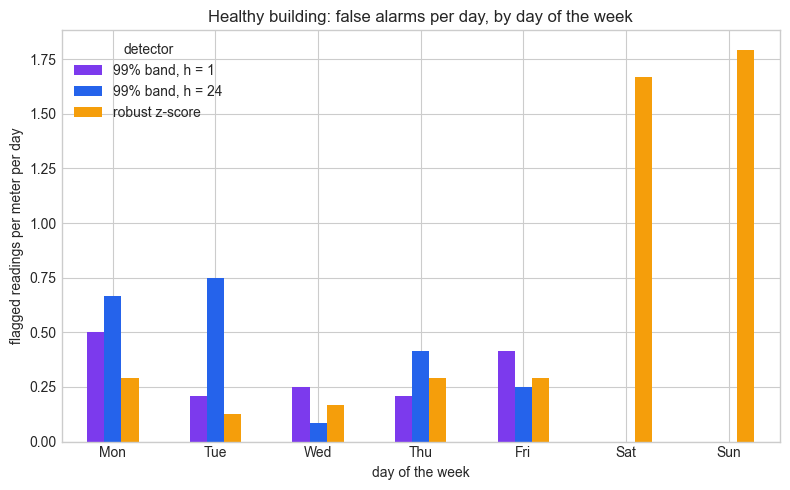

,"99% band, h = 1","99% band, h = 24",robust z-score
Mon,0.50,0.67,0.29
Tue,0.21,0.75,0.12
Wed,0.25,0.08,0.17
Thu,0.21,0.42,0.29
Fri,0.42,0.25,0.29
Sat,0.00,0.00,1.67
Sun,0.00,0.00,1.79


In [12]:
test_times = clean["building", 24].index
by_day = pd.DataFrame({
    "99% band, h = 1": outside_band(clean["building", 1], 0.01),
    "99% band, h = 24": outside_band(clean["building", 24], 0.01),
    "robust z-score": np.abs(robust_z_score(y_b, 24).loc[test_times].to_numpy()) > Z_LIMIT,
}, index=test_times).groupby(test_times.dayofweek).mean() * 24
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 5))
by_day.plot.bar(ax=ax, color=[PURPLE, BLUE, AMBER], rot=0)
ax.set_title("Healthy building: false alarms per day, by day of the week")
ax.set_xlabel("day of the week")
ax.set_ylabel("flagged readings per meter per day")
ax.legend(title="detector")
plt.tight_layout()
plt.show()
by_day.round(2)

The z-score's false alarms have a calendar: 1.67 flagged readings a day on Saturdays and 1.79
on Sundays, against 0.12 to 0.29 on weekdays. Its 14 trailing same-hour values are ten weekdays
and four weekend days, so at noon on a Saturday "normal" is a weekday noon and an empty
building looks like a fault. The bands know the day of the week (`target_dow` is one of the
model's features), and their weekends are silent: 0.00 flagged readings on Saturday and Sunday
for both 99% bands. One caution in the other direction: silent weekends next to busier weekdays
(up to 0.50 a day at h = 1 and 0.75 at h = 24) are notebook 05's marginal-versus-conditional
story again (field guide §3). The most likely reason is that the CQR offset is one number for
the whole week, sized by the weekday tails, so it over-covers the quiet weekend and
under-covers the busy weekdays. A z-score per weekday would fix the z-score's calendar at the price
of 14 weeks of history per baseline; the lasting lesson is that a "model-free" detector still
embeds a model, an unstated one in which every day is alike.

### The detectors side by side

| Detector | Plain-English rule | Caught here | Missed here | Pitfall |
|---|---|---|---|---|
| 90% band, any reading | alarm whenever a reading leaves its band | everything, eventually | nothing, including faults that never happened | 2.4 flagged readings per meter per day by design (2.15 and 1.27 events on the building); chance rate near 1.00 |
| 90% band, 3 in a row | alarm when three readings in a row are outside | steps at a median 2-2.5 hours (building) or 10 minutes (VM, h = 1, slowest 4.1 hours); building freezes | VM freezes; drifts until days in | only helps where misses do not cluster: still 17.38 flagged readings (3.38 events) a day at VM h = 12 |
| 99% band, any reading | alarm on a reading far outside | building steps at onset at h = 1 (95% at h = 24, median 5 hours); building freezes | almost everything on the VM, where bursts set the width | an extreme tail needs a long calibration window and is the first place non-exchangeability shows |
| robust z-score | alarm when far from the 14-day same-hour median | steps | VM freezes; quiet weekends look like faults | "model-free" still assumes every day is alike |
| run-length rule, L = 4 (notebook 13) | alarm when four readings in a row are identical | every freeze, at the third frozen reading (2 hours building, 10 minutes VM) | steps and drifts | innocent flat lines: 1.00 flagged reading a day from a VM saturated at exactly 100% |

No row catches everything, and the last row is not a competitor of the others. A practical
monitoring stack pairs a debounced band (steps, and freezes on rhythmic meters) with a
run-length rule (freezes everywhere) and a slower check for drift, such as a weekly comparison
of each meter's level with its own history or with its neighbours.

## 6. Choosing the band level by cost

Every rule above sits on a trade-off curve, and the band level alpha is the dial: a smaller
alpha means fewer false alarms and later detections, or none. Choosing it by taste is how the
old hand-tuned thresholds were born; choosing it by cost at least makes the taste explicit and
arguable. In words: a day of alarm duty on one meter costs the false-alarm events it raises times
what each one costs, plus the faults it lets run, times how long each runs before the first
alarm, times what an hour of a running fault costs. In symbols,

$$\text{cost}(\alpha) = \mathrm{FA}(\alpha)\, c_{\mathrm{FA}} + \lambda\, H(\alpha)\, c_H,$$

where $\mathrm{FA}(\alpha)$ is the measured number of false-alarm events per day at band level
$1 - \alpha$, $c_{\mathrm{FA}}$ the cost of one such event, $\lambda$ the number of faults
per meter per day, $H(\alpha)$ the mean number of hours a fault runs before the first alarm
(its whole window if no alarm comes), and $c_H$ the cost of one undetected fault hour.

The costs below are made up, and stated so you can change them: USD 25 per false-alarm event
(a quarter hour of triage, plus the attention it uses up), one fault per meter every 60 days,
and two prices for an undetected hour, USD 10 for an office meter (wasted energy, a wrong
purchase plan) and USD 1,000 for the meter on a server room's cooling (an hour closer to a
thermal shutdown). We sweep alpha over 0.10, 0.05, 0.01 and 0.002 for both building horizons
with the any-reading rule, over all 120 building episodes (the three fault types in equal
mix), and count any alarm inside the window as a detection: if every alarm is triaged, as the
cost of a false alarm assumes, a lucky alarm finds the fault too. The model charges per alarm
event, not per flagged reading, because a storm is triaged once; charging per reading would
make the loose bands look worse, most of all at h = 24, where storms are longest.

In [13]:
COST_PER_ALARM_EVENT = 25.0          # USD per false alarm EVENT: a storm is triaged once,
                                     # a quarter hour plus the attention it uses up
FAULTS_PER_METER_PER_DAY = 1 / 60    # one fault per meter every two months
SCENARIOS = {"office": 10.0, "server room": 1_000.0}   # USD per hour a fault runs undetected

rows = []
for h in FAMILIES["building"]["horizons"]:
    healthy_bands = clean["building", h]
    for a in BAND_ALPHAS:
        flagged_per_day, events_per_day = per_day(outside_band(healthy_bands, a), 24)
        caught, hours = [], []
        for ep, rep in zip(episodes, replays):
            if ep["family"] == "building":
                hits = np.flatnonzero(outside_band(rep[h], a))
                caught.append(hits.size > 0)
                # Any alarm in the window counts (every alarm is triaged, so a lucky one finds
                # the fault too); an uncaught fault runs its whole window.
                hours.append(hits[0] if hits.size else ep["length"])
        row = {"horizon": f"h={h}", "band": f"{1 - a:.1%}", "budget/day": 24 * a,
               "flagged/day": flagged_per_day, "events/day": events_per_day,
               "caught": np.mean(caught), "hours undetected": np.mean(hours)}
        for name, cost_hour in SCENARIOS.items():
            row[f"USD/day {name}"] = (events_per_day * COST_PER_ALARM_EVENT
                                      + FAULTS_PER_METER_PER_DAY * np.mean(hours) * cost_hour)
        rows.append(row)
cost_table = pd.DataFrame(rows).set_index(["horizon", "band"])

for name in SCENARIOS:
    best = cost_table[f"USD/day {name}"].idxmin()
    print(f"{name:>12}: cheapest = {best[0]}, {best[1]} band, "
          f"USD {cost_table.loc[best, f'USD/day {name}']:.2f} per meter per day")
fleet = {level: N_METERS * cost_table.loc[("h=1", level), "USD/day office"]
         for level in ("90.0%", "99.0%")}
print(f"3,000 office meters at h=1: USD {fleet['90.0%']:,.0f} a day with the 90% band, "
      f"USD {fleet['99.0%']:,.0f} with the 99% band")
try:   # the same sweep on the VM would need a 99.8% band from its one-day calibration window
    corrected_quantile(np.arange(288.0), 0.002)
except AssertionError as err:
    print(f"VM, alpha = 0.002 from 288 calibration readings -> AssertionError: {err}")
cost_table.round(3)

      office: cheapest = h=1, 99.0% band, USD 9.71 per meter per day
 server room: cheapest = h=24, 90.0% band, USD 156.56 per meter per day
3,000 office meters at h=1: USD 165,207 a day with the 90% band, USD 29,139 with the 99% band
VM, alpha = 0.002 from 288 calibration readings -> AssertionError: calibration window too short for this alpha (field guide S1)


budget/day  flagged/day  events/day  caught  hours undetected  USD/day office  USD/day server room
horizon band                                                                                                     
h=1     90.0%       2.400        2.577       2.155   0.983             7.200          55.069              173.869
        95.0%       1.200        1.202       1.042   0.983            10.200          27.742              196.042
        99.0%       0.240        0.226       0.220   0.975            25.242           9.713              426.200
        99.8%       0.048        0.048       0.048   0.725            54.817          10.327              914.802
h=24    90.0%       2.400        2.446       1.268   1.000             7.492          32.945              156.558
        95.0%       1.200        1.185       0.673   0.992            12.383          18.879              223.204
        99.0%       0.240        0.310       0.155   0.933            36.092           9.884              605.397
        99.8%       0.048        0.137       0.065   0.758            52.717          10.423              880.248

Two scenarios, two different answers. For the office meter the cheapest choice is the 99% band
at h = 1, USD 9.71 per meter per day: its 0.220 false-alarm events a day cost just over USD
5.50, and the faults it lets run for a mean 25.2 hours cost the rest. The 90% band at the same
horizon costs USD 55.07, nearly six times as much, almost all of it the 2.15 false-alarm events
a day; across 3,000 meters that is USD 165,207 a day against USD 29,139. Tightening further to 99.8%
saves a little on false alarms (0.048 a day) but lets 27.5% of the faults run their whole
window, and the bill climbs back to USD 10.33. For the server room an undetected hour costs a
hundred times more, and the cheapest choice flips to the loosest band: 90% at h = 24 for USD
156.56 a day, ahead of 90% at h = 1 (USD 173.87) because the day-ahead band's 2.45 flagged
readings come as only 1.27 events a day, against 2.15 for the next-hour band. Paying for 1.27
false-alarm events a day is a bargain when the alternative is a fault that runs a mean 36.1
hours instead of 7.5.

Two more readings of the table. First, the 99.8% band at h = 24 flags 0.137 readings a day
(0.065 events) against a budget of 0.048 flagged readings, nearly three times its promise,
while at h = 1 it lands on 0.048 exactly. A 99.8% band from 672 calibration readings is set by
the single largest calibration score, and the extreme tail is the first place where seasonal
and other non-exchangeable differences between a calibration window and the block after it show
up (field guide §4, §14). Second, the VM cannot even enter this sweep at 99.8%: its one-day
calibration window holds 288 readings, a 99.8% band needs at least 499, and
`corrected_quantile` refuses, as it should (field guide §1).

And the honest frame around all of it: field guide §21 says to choose the level by cost, and
how to do that well is an open question, not a solved one. The cost of a false alarm is not
constant (the hundredth page of the week costs more than the first, because it teaches the
engineer to ignore the pager); fault rates, sizes and shapes are unknown in advance and are
exactly what unlabelled traces cannot tell you; and the conformal guarantee covers only the
first term of the formula, the false-alarm rate, while the second term is an empirical property
of one forecaster against one simulated fault mix. Pieces of a theory exist: the Neyman-Pearson
view (fix the false-alarm rate you can afford, then catch as much as possible within it),
quickest change detection (methods such as CUSUM that minimise the delay to notice a change for
a given false-alarm rate), and false discovery rate control across a fleet (section 1). But
choosing a conformal alarm level from business costs, with the uncertainty in those costs
carried through, is a research question for the project, not a recipe from this notebook.

## 7. Common mistakes to avoid

1. **Promising that the band catches faults.** The conformal guarantee is about healthy
   readings only: about alpha of them leave the band (at most alpha in expectation, under
   exchangeability). Whether a fault leaves it depends on the forecaster and the fault; here
   detection ranged from every step to no VM freeze beyond chance (field guide §21).
2. **Skipping the arithmetic.** A 90% band flags about 10% of healthy readings: 2.45 a day per
   hourly meter (1.27 events), 28.25 a day per five-minute VM (7.00 events), 7,339 a day for
   3,000 meters. Do the multiplication before the meeting, not after the first night on call.
3. **Counting false alarms in one unit.** Per flagged reading the VM's z-score (27.88 a day)
   is nearly as noisy as its h = 1 90% band (30.25); per alarm event it is less than a third as noisy
   (7.12 against 25.50). Report both, and say which one a cost model charges (field guide §21).
4. **Quoting a detection rate without its chance rate.** The any-reading rule "detected" every
   drift, and flagged a reading in every one of the same windows on healthy data. Score every
   rule against the same windows with no fault injected. And when the chance rate is high,
   compare timing before calling a detection luck: the VM's three-in-a-row rule flagged a
   healthy reading in 36 of its 40 drift windows, yet its alarm came first in 26 of them, at a
   median 12.2 hours against 21.8 for the first false alarm.
5. **Alarming against a forecast that has already read the fault.** The persistence band
   alarmed on 0.00 of the frozen readings and fell back to the healthy rate one reading after a
   step. Plot the alarm share by hours since onset for every forecaster you consider, prefer
   forecasts issued before the fault, and then measure: on this building the narrower h = 1
   GBM still caught the onset better (the horizon trade-off of field guide §21).
6. **Reading a quiet dashboard as a healthy fleet.** A frozen VM raised fewer alarms than a
   healthy one. Pair the band with a minimum-run-length rule, which caught every freeze at the
   third frozen reading (notebook 13, field guide §20).
7. **Debouncing a series whose misses cluster.** Three in a row cut the building's h = 1
   flagged readings from 2.58 to 0.13 a day but left the VM's h = 12 band at 17.38 (3.38
   events), because its misses arrive in storms of 4.04 readings. Measure storm lengths before
   choosing k.
8. **Asking a short calibration window for an extreme tail.** A 99.8% band needs at least 499
   calibration scores, which the VM's 288 cannot supply; and even from 672 scores, the h = 24
   building band flagged 0.137 readings a day against a budget of 0.048 (field guide §1, §4).
9. **Quoting injected-fault results as field performance.** Injected faults are cleaner than
   real ones, and the public traces have no fault labels. Report the numbers as best cases on
   simulated faults, and say so.

## 8. What to say in the project report

**Strong version**

> We evaluated walk-forward conformalized quantile bands (gradient boosting + CQR) as alarm
> limits on a simulated hourly building meter and a simulated 5-minute VM, replaying 40
> injected faults per type (steps, freezes, drifts) through models fitted on clean data, and
> counted false alarms both as flagged readings and as alarm events (runs of flagged
> readings). Used as-is, the 90% band flagged 2.45 healthy building readings per meter per day
> (budget 2.4) in 1.27 alarm events, about 7,300 false alarms (3,800 events) a day across
> 3,000 meters, and 28.25 readings (7.00 events) per VM per day at the one-hour horizon; on
> building fault windows its detection rate was within 8 points of its chance rate. Requiring
> three consecutive exceedances of the next-hour band cut building false alarms to 0.13
> flagged readings (0.08 events) per day while detecting all 30% steps (median delay 2.5 h,
> chance rate 0.15), 92% of 48-hour freezes (9 h) and all week-long 30% drifts (66.5 h); on
> the VM the same rule detected all 50% steps, median delay 10 minutes (slowest 4.1 h), at
> 0.75 flagged readings (0.62 events) per day. No band and no robust z-score baseline (0.66 and
> 27.88 flagged readings per day) detected VM freezes above chance (none caught more freezes than
> its chance control; the quietest band rule caught 5 of 40, against 8 of the same 40 windows
> flagged on healthy data), while a four-reading stuck-value rule caught every freeze at
> the third frozen reading; freezes need that separate rule. The conformal guarantee bounds
> only the false-alarm rate, in expectation; detection depends on the forecaster, which partly
> follows a fault through its own inputs. All faults were injected and cleaner than real ones.
> With stated, illustrative costs charged per false-alarm event, the cost-minimising band moved
> from 99% (next hour) to 90% (day ahead) as the cost of an undetected hour rose from USD 10 to
> USD 1,000; choosing the level from real costs remains open.

**Weak version**

> Conformal bands give guaranteed fault detection at 90% confidence, so we replaced the
> hand-tuned thresholds with the band edges. In our tests the bands detected 100% of steps,
> freezes and drifts.

The weak version turns a guarantee about false alarms into a promise about faults, which no
conformal theorem makes. Its "100%" is the any-reading rule, whose chance rate on the same
windows was also 1.00; it never mentions the false alarms in either unit (2.4 flagged readings
or 1.27 events per meter per day, about 7,300 flagged readings a day for the fleet); it
averages away the fault types, hiding that VM freezes were never caught above chance; and it
reports simulated faults as if they were field performance.

### The one-line summary

A calibrated band becomes an alarm limit in one line of code, and it keeps exactly one promise,
approximately: on healthy readings, about alpha of them alarm (at most alpha in expectation,
under exchangeability). At 90% that promise is 2.4 flagged readings per meter per day, fewer
alarm events when the flags cluster, so the alarm worth deploying is a debounced or stricter
edge whose level is chosen by cost. What the band catches is not promised at all; it depends on
a forecaster that reads the very readings a fault corrupts. Persistence absorbed a step after
one reading and never saw a freeze, the boosting model chased part of the way, and the
day-ahead forecast held on longest but paid for its width at the onset. Steps were caught at once,
building freezes within hours, drifts after days, and VM freezes no better than chance, while a
four-reading stuck-value rule caught every freeze at the third frozen reading: that job belongs
to notebook 13.

An alarm limit is a promise about false alarms, and only a hope about faults.